# 06 - Simpan Model: Raw dan Standar Hugging Face

**Tujuan:** Menyimpan model terbaik dalam dua bentuk, membuat model card, dan mengetes bahwa export bisa dimuat ulang.

| | |
|---|---|
| **Input** | `checkpoints/best.pt`, `labels.json`, `test_metrics.json` |
| **Output** | `models/raw/` (non-standar) dan `models/hf_export/` (standar HF + model card) |
| **Prasyarat** | Notebook 05 |

> Setiap notebook berdiri sendiri: ia membaca hasil notebook sebelumnya dari Google Drive, jadi sesi Colab boleh diputus/diulang di antara notebook.

In [1]:
# --- Bootstrap (sama di setiap notebook) ---------------------------------------
# 1) Sambungkan Google Drive (tempat semua hasil disimpan permanen)
import os, sys, zipfile
from google.colab import drive
drive.mount('/content/drive')

# 2) Lokasi di Drive: folder ini sekaligus ROOT proyek (zip dan semua hasil ada di sini)
ROOT_ON_DRIVE = "/content/drive/MyDrive/models-train/mmfood-multitask"
ZIP_ON_DRIVE = f"{ROOT_ON_DRIVE}/mmfood-multitask.zip"

# 3) Folder hasil = ROOT di Drive. Harus diset SEBELUM mengimpor config
os.environ["MMFOOD_PROJECT"] = ROOT_ON_DRIVE

# 4) Ekstrak kode + dataset dari zip ke disk lokal Colab (hanya sekali per sesi)
REPO = "/content/mmfood-multitask"
if not os.path.exists(REPO):
    with zipfile.ZipFile(ZIP_ON_DRIVE) as z:
        z.extractall("/content")

# 5) Daftarkan folder src/ agar modul proyek bisa di-import
sys.path.insert(0, f"{REPO}/src")

# 6) Muat path folder (P) dan konfigurasi (CFG) dari src/config.py
from config import get_paths, load_cfg
P = get_paths()       # P.processed, P.checkpoints, P.hf_export, ... (folder dibuat otomatis)
CFG = load_cfg(P)     # nilai bawaan + perubahan dari notebook 00
print("Folder hasil:", P.project)

Mounted at /content/drive
Folder hasil: /content/drive/MyDrive/models-train/mmfood-multitask


In [2]:
# Install library yang dibutuhkan (Colab biasanya sudah punya sebagian; -q = senyap)
!pip install -q transformers accelerate huggingface_hub safetensors scikit-learn pillow tqdm matplotlib

## Langkah 6.1 - Muat model terbaik

In [3]:
import json, shutil
import pandas as pd
import torch
from PIL import Image
from transformers import AutoImageProcessor
from train_utils import build_model
from modeling_mmfood import MMFoodConfig, MMFoodMultiTask
from images import restore_images

device = "cuda" if torch.cuda.is_available() else "cpu"
LABELS = json.load(open(f"{P.artifacts}/labels.json"))
PRE = json.load(open(f"{P.artifacts}/preprocess.json"))
METRICS = json.load(open(f"{P.metrics}/test_metrics.json"))

# Bangun model dan isi bobot terbaik
model, model_cfg = build_model(CFG, LABELS, device, pretrained_backbone=False)
model.load_state_dict(torch.load(f"{P.checkpoints}/best.pt", map_location=device)["model"])
model.eval()
processor = AutoImageProcessor.from_pretrained(CFG["backbone_name"])
print("Model dimuat.")

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

Model dimuat.


## Langkah 6.2 - Simpan versi RAW (belum standar Hugging Face)
Cadangan apa adanya: satu file `.pt` berisi bobot + konfigurasi + label + statistik nutrisi + pra-proses. Bisa dimuat dengan PyTorch murni tanpa library Hugging Face. Folder: `models/raw/`.

In [4]:
# Satu file lengkap: bobot + semua metadata yang dibutuhkan untuk inferensi
torch.save({"state_dict": model.state_dict(), "config": model_cfg.to_dict(), "labels": LABELS,
            "image_mean": PRE["image_mean"], "image_std": PRE["image_std"], "img_size": PRE["img_size"],
            "test_metrics": METRICS["test"]},
           f"{P.raw_model}/mmfood_multitask_raw.pt")

# Salinan label dan konfigurasi training dalam JSON agar mudah dibaca manusia
json.dump(LABELS, open(f"{P.raw_model}/labels.json", "w"), indent=2)
json.dump(CFG, open(f"{P.raw_model}/training_config.json", "w"), indent=2)
print("models/raw:", sorted(os.listdir(P.raw_model)))

models/raw: ['labels.json', 'mmfood_multitask_raw.pt', 'training_config.json']


## Langkah 6.3 - Simpan versi STANDAR Hugging Face
`save_pretrained()` menghasilkan struktur repo standar:

```
models/hf_export/
|- config.json              konfigurasi + auto_map untuk kelas kustom
|- model.safetensors        bobot (format aman)
|- preprocessor_config.json mean/std/ukuran gambar
|- modeling_mmfood.py       kode arsitektur kustom (disalin otomatis)
|- labels.json              pemetaan label
|- README.md                model card (langkah 6.5)
```
Karena arsitektur kustom, pemuatan dari Hub memakai `trust_remote_code=True`.

In [5]:
import os
EXPORT = P.hf_export
shutil.rmtree(EXPORT, ignore_errors=True); os.makedirs(EXPORT)   # mulai dari folder bersih

# Daftarkan kelas kustom agar kodenya ikut tersimpan + auto_map terisi di config.json
MMFoodConfig.register_for_auto_class()
MMFoodMultiTask.register_for_auto_class("AutoModel")
model.config.architectures = ["MMFoodMultiTask"]

model.save_pretrained(EXPORT, safe_serialization=True)   # config.json + model.safetensors + modeling_mmfood.py
processor.save_pretrained(EXPORT)                         # preprocessor_config.json
json.dump(LABELS, open(f"{EXPORT}/labels.json", "w"), indent=2)
print(sorted(os.listdir(EXPORT)))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['config.json', 'labels.json', 'model.safetensors', 'modeling_mmfood.py', 'preprocessor_config.json']


## Langkah 6.4 - Tes: muat ulang hasil export
Prediksi model hasil muat ulang harus sama dengan model asli (selisih ~0).

In [6]:
from transformers import AutoModel

# Muat dari folder export persis seperti yang akan dilakukan orang lain dari Hub
reloaded = AutoModel.from_pretrained(EXPORT, trust_remote_code=True).to(device).eval()

# Input acak sebagai uji kesetaraan numerik
x = torch.randn(2, 3, PRE["img_size"], PRE["img_size"], device=device)
with torch.no_grad():
    a = model(x)["nutrition_pred"].float()
    b = reloaded(x)["nutrition_pred"].float()
print("Selisih maksimum:", (a - b).abs().max().item(), "(harus ~0)")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

Selisih maksimum: 0.0 (harus ~0)


## Langkah 6.5 - Model card
`README.md` di repo HF dibuat dari `docs/MODEL_CARD_TEMPLATE.md` dan diisi metrik hasil test. **Baca dan edit manual** sebelum upload (klaim harus sesuai hasil, keterbatasan ditulis jujur).

In [7]:
# Baca template dan isi placeholder {{...}} dengan nilai nyata
tmpl = open(f"{REPO}/docs/MODEL_CARD_TEMPLATE.md", encoding="utf-8").read()
tm, bm = METRICS["test"], METRICS["baseline_mae"]
n_val = len(pd.read_csv(f"{P.processed}/val.csv"))
fill = {
    "{{REPO_ID}}": f"{CFG['hf_username']}/{CFG['model_name']}",
    "{{BACKBONE}}": CFG["backbone_name"],
    "{{N_TRAIN}}": str(METRICS["n_train"]), "{{N_VAL}}": str(n_val), "{{N_TEST}}": str(METRICS["n_test"]),
    "{{EPOCHS}}": str(CFG["epochs"]), "{{BATCH}}": str(CFG["batch_size"]),
    "{{LR_BB}}": str(CFG["lr_backbone"]), "{{LR_HEAD}}": str(CFG["lr_heads"]), "{{TOP_K}}": str(CFG["top_k_dish"]),
    "{{ACC_FOOD}}": f"{tm['acc_food_type']:.3f}", "{{ACC_DISH}}": f"{tm['acc_dish']:.3f}", "{{ACC_COOK}}": f"{tm['acc_cooking']:.3f}",
    "{{MAE_CAL}}": f"{tm['mae_calories_kcal']:.1f}",   "{{BASE_CAL}}": f"{bm['calories_kcal']:.1f}",
    "{{MAE_PRO}}": f"{tm['mae_protein_g']:.1f}",       "{{BASE_PRO}}": f"{bm['protein_g']:.1f}",
    "{{MAE_FAT}}": f"{tm['mae_fat_g']:.1f}",           "{{BASE_FAT}}": f"{bm['fat_g']:.1f}",
    "{{MAE_CARB}}": f"{tm['mae_carbohydrate_g']:.1f}", "{{BASE_CARB}}": f"{bm['carbohydrate_g']:.1f}",
}
for k, v in fill.items():
    tmpl = tmpl.replace(k, v)
assert "{{" not in tmpl, "Masih ada placeholder yang belum terisi"

# Simpan sebagai README.md di folder export (jadi halaman utama repo HF)
open(f"{EXPORT}/README.md", "w", encoding="utf-8").write(tmpl)
print(tmpl[:900])

---
license: openrail
library_name: transformers
pipeline_tag: image-classification
base_model: facebook/convnext-tiny-224
datasets:
  - Codatta/MM-Food-100K
tags:
  - food
  - multi-task
  - image-classification
  - nutrition-estimation
metrics:
  - accuracy
  - mae
language:
  - en
---

# GANTI_USERNAME_HF/convnext-tiny-mmfood-multitask

Model multi-task yang menerima **satu foto makanan** dan memprediksi: jenis makanan (`food_type`), nama hidangan (Top-50), metode masak, serta estimasi nutrisi (kalori, protein, lemak, karbohidrat).

> Proyek pembelajaran/penelitian. **Bukan** alat medis atau gizi. Estimasi nutrisi dari satu foto kasar dan tidak boleh dipakai untuk keputusan kesehatan.

## Cara pakai

```python
import torch
from PIL import Image
from transformers import AutoModel, AutoImageProcessor

repo = "GANTI_USERNAME_HF/convnext-tiny-mmfood-multitask"
model = AutoModel.from_pretr


## Langkah 6.6 - Coba inferensi pada satu gambar test

{
  "food_type": [
    [
      "Homemade food",
      0.9768576622009277
    ],
    [
      "Restaurant food",
      0.021978674456477165
    ],
    [
      "Packaged food",
      0.0006858015549369156
    ]
  ],
  "dish_name": [
    [
      "chicken stir-fry",
      0.46006909012794495
    ],
    [
      "vegetable stir-fry",
      0.13146939873695374
    ],
    [
      "stir-fried chicken with vegetables",
      0.11155077815055847
    ]
  ],
  "cooking_method": [
    [
      "stir-fry",
      0.8906240463256836
    ],
    [
      "other",
      0.031868238002061844
    ],
    [
      "boil",
      0.028681300580501556
    ]
  ],
  "nutrition": {
    "calories_kcal": 280.5,
    "protein_g": 14.5,
    "fat_g": 15.7,
    "carbohydrate_g": 19.4
  }
}
Label asli: Scrambled Eggs with Tomatoes | Homemade food | {'calories_kcal': 250.0, 'protein_g': 12.0, 'fat_g': 15.0, 'carbohydrate_g': 20.0}


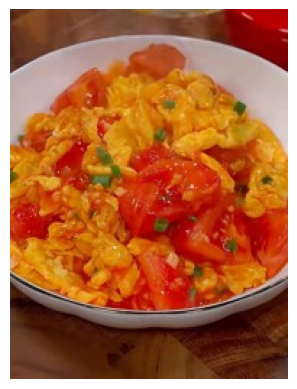

In [8]:
import matplotlib.pyplot as plt
from dataset import get_transforms

restore_images(P.local_images, f"{P.image_cache}/images.tar")
test_df = pd.read_csv(f"{P.processed}/test.csv")
_, eval_tf = get_transforms(PRE["image_mean"], PRE["image_std"], PRE["img_size"])

# Ambil satu gambar test, jalankan model hasil export, tampilkan prediksi vs label asli
r = test_df.iloc[0]
img = Image.open(f"{P.local_images}/{r.fname}").convert("RGB")
x = eval_tf(img).unsqueeze(0).to(device)
print(json.dumps(reloaded.predict(x, topk=3)[0], indent=2))
print("Label asli:", r.dish_name, "|", r.food_type, "|", r[["calories_kcal", "protein_g", "fat_g", "carbohydrate_g"]].to_dict())
plt.imshow(img); plt.axis("off"); plt.show()